> **이 노트북의 출력은 새로 통째로 받은 데이터(`data\통합_전체_202611`)로 지금 코드로 다시 돌린 결과다(2026-11-05).** 같은 실험을 더 넓게 한 것은 `확장연구_20261103.ipynb`다. 요약표용 결과는 `결과_월수익률/연구_이로운_*.pkl`, 예전 합친 데이터(2026-11-02) 결과는 `결과_월수익률/_예전_20261102/`에 있다.

# 이로운: 지표 바꾸기 (가치 자리·퀄리티 자리)
연구_틀(`연구_틀.ipynb`)을 복사해 **0번(실험 기록)과 3번(설정) 칸만** 바꾸고, 10번부터 실험 칸을 더했다. 공통 계산(`공통/`)은 이 노트북에서 바꾸지 않는다.

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW는 회원 결정(2026-11-06)으로 뺌, t는 OLS, TR(배당 포함 수정주가).

## 0. 실험 기록 [바꾸는 칸]
누가, 언제, 무엇을 왜 바꾸는지 적는다. 저장 파일 이름(이름_날짜_실험명.csv)에 쓰인다.

In [1]:
실험 = dict(
    이름="이로운",
    날짜="2026-11-02",
    실험명="지표바꾸기",
    무엇을="마법공식의 가치 자리(EY)와 퀄리티 자리(ROC)를 다른 지표로 바꾼 조합(경제적 이유가 있는 것만)",
    왜="어느 가치·퀄리티 지표 조합이 고르는 기간에 좋았고, 그 뒤 검증 기간에도 유지되는지 보려고",
)

## 1. 데이터 경로 [바꾸는 칸]
기본은 새로 통째로 받은 파일(`data\통합_전체_202611`)이다. 시험 데이터로 빨리 볼 때만 주석을 푼다.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import 데이터읽기 as 읽기
# 시험 데이터로 빨리 볼 때: 읽기.DATA = Path.cwd().parent / "_시험데이터"
print(읽기.DATA)

D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611


## 2. 공통 불러오기 [건드리지 않는 칸]

In [3]:
import json
import pandas as pd
import 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

## 3. 설정 [바꾸는 칸]
`포.기본설정`에서 바꿀 것만 적는다. 쓸 수 있는 값:
- 시장: `"KS"`(유가증권), `"KQ"`(코스닥) / 기준일: `"첫거래일"`, `"마지막거래일"` / 리밸런싱: 1·3·12(달)
- 제외: `종목거르기.py`의 함수 이름 — 보통주, 스팩, 금융업, 투자기구, 결산월, 거래정지, 관리종목, 동전주, 자본잠식, 회전율, 거래대금, 시총상위, 시총분위, 종목빼기 (옵션은 `("이름", {옵션})`). `시장`과 `쓰지말것`(README_데이터 '쓰지 말 것' 구간)은 항상 먼저 적용된다
- 지표와 방향: `지표.py`의 함수 이름 + `"높게"`/`"낮게"` (단계별이면 셋째 값 = 남길 비율)
- 합산: `"순위합산"`, `"z합산"`, `"단계별"` / 고르기: `("상위N", n)`, `("분위", k)`
- 재무시점: `("결산후개월", k)`(결산일 + k개월, 발표일 안 봄) | `("발표일", k)`(발표일 다음 거래일, 없으면 결산일 + k일. k = 150 본문, 180 확인)
- 비중: `"동일"`, `"시총"`, `"시총상한"`(비중상한), `"시총상한10"`·`"시총상한30"`, `"위험균형"`(직전 12개월 변동성 역수), `"최소분산"`(공매도 없음, 직전 36개월 월수익률, Ledoit-Wolf 수축) / 거래비용: 수수료·거래세·슬리피지(·월비용) / 전량교체: `True`면 리밸런싱 때 전부 팔고 새로 삼(우동호 원문), `False`면 바뀐 만큼만

In [4]:
설정 = {**포.기본설정,
    "이름": 실험["실험명"],
    "기간": ("2004-04", "2026-09"),
    "시장": ["KS", "KQ"],
    "기준일": "첫거래일",
    "리밸런싱": 12,
    "재무시점": ("발표일", 150),  # 1999년 이전은 발표일 기록이 거의 없어 결산일 + 150일(통합_확인기록 F8)
    "제외": ["보통주", "금융업", "투자기구", ("결산월", {"월": 12}), "거래정지"],
    "고르기": ("상위N", 30),
    "거래비용": dict(수수료=0.00015, 거래세=0.0025, 슬리피지=0.005),
    "지표": [("EY", "높게"), ("ROC", "높게")],  # 기준(그린블라트 원래 공식). 조합은 아래 표
    "합산": "순위합산",
    "비중": ["동일", "시총"],
}
# 돌릴 조합(가치 함수, 퀄리티 함수, 경제적 이유). 함수는 공통/지표.py: EP=E/P, BP=B/M, SP=S/P, CFP=CF/P, EBITDA_EV=EBITDA/EV, ROA, GPA=GP/A, 영업CF자산=영업현금흐름/자산
조합 = pd.DataFrame([
    ("EY", "ROC", "기준: 그린블라트 원래 공식. 둘 다 기업 전체(부채 포함) 기준 — 이익/기업가치, 이익/투하자본"),
    ("EY", "GPA", "우동호 IMF. 매출총이익은 비용 분류·일회성 항목의 영향이 적은 수익성(Novy-Marx 2013)"),
    ("EY", "영업CF자산", "이익이 현금으로 뒷받침되는 회사 고르기(발생액이 큰 회사 피하기, Sloan 1996)"),
    ("EBITDA_EV", "ROC", "둘 다 기업 전체 기준. 가치 쪽을 감가상각 정책 차이를 덜 타는 EBITDA로"),
    ("EBITDA_EV", "GPA", "둘 다 감가상각·이자 전 이익 → 자본구조·감가상각 정책 영향 줄임"),
    ("EP", "ROE", "둘 다 주주 기준(순이익). P/B = P/E × ROE라 낮은 P/E와 높은 ROE를 함께 보면 '수익성 대비 싼 장부가'"),
    ("EP", "ROA", "순이익 기준끼리. 빚으로 부풀린 ROE 대신 자산 대비 순이익"),
    ("BP", "ROE", "Fama-French 5요인의 HML(B/M)·RMW(수익성) 결합. 분모가 같은 장부가"),
    ("BP", "GPA", "Novy-Marx(2013) 가치 + 수익성(04 신마법공식). 두 요인의 상관이 음수라 분산 효과"),
    ("SP", "영업이익률", "P/S가 낮아도 마진이 낮으면 싼 이유가 있음 → 마진으로 거름(P/E = P/S ÷ 순이익률)"),
    ("CFP", "영업CF자산", "둘 다 영업현금흐름 기준 → 회계 발생액의 영향 줄임"),
], columns=["가치", "퀄리티", "경제적 이유"])
고르는기간, 검증기간 = ("2004-04", "2017-03"), ("2017-04", None)  # 보유 월 기준
# 고르는 기준(돌리기 전에 정함): 고르는 기간 동일가중 샤프가 가장 높은 조합 1개 → 검증 기간 성과를 따로 본다

## 4. 새 지표 [바꾸는 칸]
이 실험은 새 지표를 만들지 않는다(`공통/지표.py`의 함수만 씀).

In [5]:
# 새 지표 없음

## 5. 실행 [건드리지 않는 칸]

In [6]:
결과 = 포.실행(설정)
F = 평가.요인(포.기준일(결과["설정"]), 결과["설정"])
R = pd.DataFrame({f"{b}_{g}": 결과["수익률"][(b, g)] for b, g in 결과["수익률"]})
if 설정["고르기"][0] == "분위":  # LS는 거래비용 0으로 다시 돌려 만든다(비용 뺀 Q5를 빼면 숏 쪽 비용 부호가 거꾸로 됨)
    g = 포.실행({**설정, "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)})["수익률"]
    for b in 설정["비중"]:
        R[f"{b}_LS(비용0)"] = g[(b, "Q1")] - g[(b, f"Q{설정['고르기'][1]}")]
R["시장"] = F["시장"]
R = R.dropna(how="all")

## 6. 결과표·누적수익률 그림 [건드리지 않는 칸]

,이상값 보유,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),...,FF3 t(NW보정),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart t(NW보정),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
동일_상위30,0.0000,269.0000,6.2472,0.0924,0.2588,0.3727,-0.5779,0.0301,0.0080,1.7645,...,0.5845,0.0025,0.9143,0.9991,0.9898,0.9095,0.8919,0.0717,-0.1957,0.6729
시총_상위30,0.0000,269.0000,9.1867,0.1091,0.3112,0.3995,-0.6083,0.1301,0.0104,1.8917,...,0.7458,0.0044,0.9537,1.0211,1.0115,0.8914,0.4121,0.0874,-0.2055,0.3566
시장,NaN,269.0000,6.7438,0.0956,0.2222,0.4053,-0.5062,NaN,0.0075,1.9189,...,NaN,0.0000,NaN,NaN,NaN,1.0000,0.0000,0.0000,0.0000,1.0000


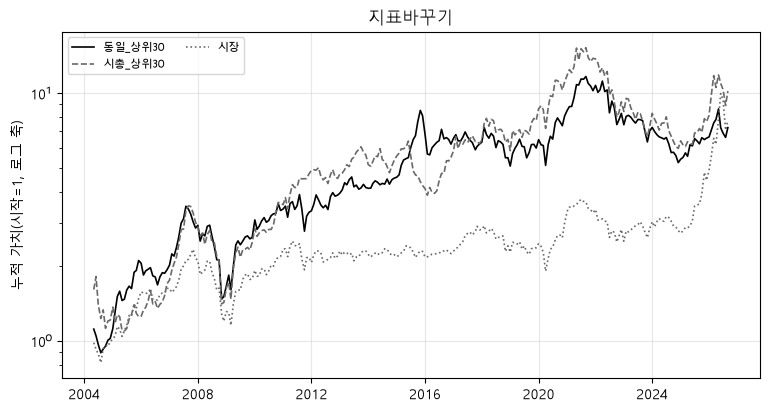

In [7]:
표 = 평가.성과표(R, F, [c for c in R if "_LS" in c])
표.insert(0, "이상값 보유", pd.Series({f"{b}_{g}": n for (b, g), n in 포.이상값보유(결과).items()}))  # +300% 종목-월 보유 건수(README 한계 '이상값 보유 칸')
평가.누적그림(R, 설정["이름"]);
표

## 7. 같은 기간 기준과 자동 비교 [건드리지 않는 칸]
같은 기간으로 우동호(2023) 재현과 시장을 돌려 나란히 놓는다. 무위험이자율과 전량교체 여부는 3번 칸 설정 것을 쓴다.
기준은 두 줄이다. **본문 설정**은 우동호 그대로(배당 빠진 수정주가, 결산 후 3개월), **같은 가격·재무시점**은 가격 계열과 재무시점까지 3번 칸 설정에 맞춘 것. 두 기준의 차이는 배당 포함 여부와 재무시점 차이에서 나온다. 실험 효과는 '같은 가격·재무시점' 줄과 비교한다.
기간 안에서 개월 수가 다를 수 있다(개월 칸 확인. 첫 리밸런싱에 종목이 없으면 그 구간은 빈칸).

In [8]:
기준 = {**포.우동호2023, "기간": 설정["기간"], "무위험": 설정["무위험"], "전량교체": 설정["전량교체"]}
기준들 = {f"기준:{기준['이름']}(본문 설정)": 기준, f"기준:{기준['이름']}(같은 가격·재무시점)": {**기준, "가격": 설정["가격"], "재무시점": 설정["재무시점"]}}
Fb = 평가.요인(포.기준일(기준), 기준)
기준표 = 평가.성과표(pd.DataFrame({k: 포.실행(v)["수익률"][("동일", "상위30")] for k, v in 기준들.items()} | {"기준:시장": Fb["시장"]}).dropna(how="all"), Fb)
비교 = pd.concat([표, 기준표])
비교[["개월", "누적", "연환산", "표준편차(연)", "샤프", "MDD", "정보비율", "Carhart α(월)", "Carhart t(OLS)"]]

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,Carhart α(월),Carhart t(NW)
동일_상위30,269.0000,6.2472,0.0924,0.2588,0.3727,-0.5779,0.0301,0.0025,0.9991
시총_상위30,269.0000,9.1867,0.1091,0.3112,0.3995,-0.6083,0.1301,0.0044,1.0211
시장,269.0000,6.7438,0.0956,0.2222,0.4053,-0.5062,NaN,0.0000,NaN
기준:우동호2023_MF(본문 설정),269.0000,4.3226,0.0774,0.2593,0.3190,-0.5895,-0.0348,0.0013,0.4985
기준:우동호2023_MF(같은 가격·재무시점),269.0000,6.2472,0.0924,0.2588,0.3727,-0.5779,0.0301,0.0025,0.9991
기준:시장,269.0000,6.7438,0.0956,0.2222,0.4053,-0.5062,NaN,0.0000,NaN


## 8. 확인 [건드리지 않는 칸]
리밸런싱마다 단계별 남은 종목 수, 지표별 빈칸 수, 빈칸 때문에 빠진 수, 편입 수.

In [9]:
결과["기록"].T

기준일,2004-04-01,2005-04-01,2006-04-03,2007-04-02,2008-04-01,2009-04-01,2010-04-01,2011-04-01,2012-04-02,2013-04-01,...,2017-04-03,2018-04-02,2019-04-01,2020-04-01,2021-04-01,2022-04-01,2023-04-03,2024-04-01,2025-04-01,2026-04-01
가격있음,1754,1756,1801,1872,1952,1981,1966,1970,1970,1929,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
시장,1754,1756,1801,1872,1952,1981,1966,1970,1970,1929,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
쓰지말것,1753,1755,1800,1871,1951,1980,1965,1969,1969,1928,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
보통주,1573,1584,1634,1707,1781,1810,1806,1816,1818,1781,...,1992,2044,2121,2210,2298,2373,2456,2558,2640,2660
금융업,1490,1507,1555,1627,1696,1728,1718,1712,1723,1706,...,1865,1851,1915,2021,2106,2179,2247,2335,2402,2437
투자기구,1484,1485,1519,1578,1647,1682,1672,1670,1681,1662,...,1842,1841,1903,2008,2090,2158,2224,2312,2379,2414
결산월,1372,1396,1441,1504,1566,1603,1600,1606,1625,1613,...,1802,1805,1866,1968,2050,2120,2187,2276,2346,2384
거래정지,1334,1345,1402,1475,1523,1505,1533,1569,1579,1568,...,1766,1767,1807,1874,1948,2024,2126,2191,2260,2292
빈칸:EY,80,98,108,118,128,98,104,128,85,78,...,124,124,132,20,14,14,14,24,27,28
빈칸:ROC,297,305,306,308,322,299,301,318,107,92,...,147,147,151,40,33,32,39,46,51,52


## 9. 저장 [건드리지 않는 칸]
설정과 결과를 `연구/결과/이름_날짜_실험명.csv`에 남긴다. 같은 이름이 있으면 뒤에 번호를 붙인다(덮어쓰지 않음).

In [10]:
out = Path.cwd() / "결과"
f = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}.csv"
i = 1
while f.exists():
    f, i = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}_{i}.csv", i + 1
비교.assign(실험기록=json.dumps(실험, ensure_ascii=False), 설정=json.dumps(설정, ensure_ascii=False, default=str)).to_csv(f, encoding="utf-8-sig")
print("저장:", f)

저장: D:\26-2_데이터기반투자전략\과제02\과제02_백테스트\연구\결과\이로운_2026-11-02_지표바꾸기_3.csv


## 10. 조합 실행과 고르는 기간·검증 기간 성과 [실험 칸]
조합마다 같은 설정으로 돌린다(지표만 바꿈). 성과는 보유 월로 두 기간을 나눠 따로 계산한다: 고르는 기간 2004-04~2017-03, 검증 기간 2017-04~.
돌린 조합은 아래 표의 전부다(빼고 보고한 조합 없음).

In [11]:
이름들 = 조합["가치"] + "+" + 조합["퀄리티"]
display(조합.set_index(이름들.rename("조합")))
조합결과 = {n: 결과 if (v, q) == ("EY", "ROC") else 포.실행({**설정, "이름": n, "지표": [(v, "높게"), (q, "높게")]})
           for n, v, q in zip(이름들, 조합["가치"], 조합["퀄리티"])}
열 = ["개월", "누적", "연환산", "표준편차(연)", "샤프", "MDD", "Carhart α(월)", "Carhart t(OLS)"]
표들 = {k: 평가.성과표(pd.DataFrame({(n, w): 평가.구간(o["수익률"][(w, "상위30")].dropna(), a, b) for n, o in 조합결과.items() for w in 설정["비중"]}), F)[열]
       for k, (a, b) in {"고르는 기간": 고르는기간, "검증 기간": 검증기간}.items()}
pd.concat(표들, axis=1)

,가치,퀄리티,경제적 이유
조합,,,
EY+ROC,EY,ROC,기준: 그린블라트 원래 공식. 둘 다 기업 전체(부채 포함) 기준 — 이익/기업가치...
EY+GPA,EY,GPA,우동호 IMF. 매출총이익은 비용 분류·일회성 항목의 영향이 적은 수익성(Novy-...
EY+영업CF자산,EY,영업CF자산,"이익이 현금으로 뒷받침되는 회사 고르기(발생액이 큰 회사 피하기, Sloan 1996)"
EBITDA_EV+ROC,EBITDA_EV,ROC,둘 다 기업 전체 기준. 가치 쪽을 감가상각 정책 차이를 덜 타는 EBITDA로
EBITDA_EV+GPA,EBITDA_EV,GPA,둘 다 감가상각·이자 전 이익 → 자본구조·감가상각 정책 영향 줄임
EP+ROE,EP,ROE,둘 다 주주 기준(순이익). P/B = P/E × ROE라 낮은 P/E와 높은 RO...
EP+ROA,EP,ROA,순이익 기준끼리. 빚으로 부풀린 ROE 대신 자산 대비 순이익
BP+ROE,BP,ROE,Fama-French 5요인의 HML(B/M)·RMW(수익성) 결합. 분모가 같은 장부가
BP+GPA,BP,GPA,Novy-Marx(2013) 가치 + 수익성(04 신마법공식). 두 요인의 상관이 ...


고르는 기간                                                                     검증 기간                                                                   
                       개월      누적    연환산 표준편차(연)     샤프     MDD Carhart α(월) Carhart t(NW)       개월      누적     연환산 표준편차(연)      샤프     MDD Carhart α(월) Carhart t(NW)
EY+ROC        동일 156.0000  5.4006 0.1535  0.2695 0.5581 -0.5779       0.0031        0.7322 113.0000  0.1323  0.0133  0.2426  0.0903 -0.5510       0.0005        0.1788
              시총 156.0000  5.3712 0.1531  0.3260 0.5019 -0.5986       0.0080        1.2241 113.0000  0.5989  0.0511  0.2901  0.2416 -0.6083      -0.0001       -0.0211
EY+GPA        동일 156.0000  9.5799 0.1990  0.2555 0.7204 -0.5326       0.0055        1.4076 113.0000  0.3427  0.0318  0.2112  0.1562 -0.4473       0.0018        0.5865
              시총 156.0000 13.5795 0.2289  0.2365 0.8665 -0.2952       0.0089        1.6489 113.0000  0.1871  0.0184  0.2428  0.1101 -0.5834      -0.0002       -0.0483
EY+영업CF자산     동일 156.0000  6.1604 0.1635  0.2490 0.6137 -0.5514       0.0049        1.6246 113.0000  0.4311  0.0388  0.2431  0.1932 -0.4253       0.0023        0.8042
              시총 156.0000  8.7486 0.1914  0.3025 0.6364 -0.5699       0.0082        1.6781 113.0000  0.2441  0.0235  0.2632  0.1386 -0.6270       0.0004        0.0886
EBITDA_EV+ROC 동일 156.0000  4.6094 0.1418  0.2350 0.5551 -0.5317       0.0040        1.2704 113.0000 -0.1346 -0.0152  0.2411 -0.0281 -0.5080      -0.0027       -0.9471
              시총 156.0000  3.3779 0.1203  0.2308 0.4799 -0.3815       0.0060        1.4360 113.0000  2.5990  0.1457  0.3660  0.4770 -0.5552       0.0050        0.9205
EBITDA_EV+GPA 동일 156.0000  8.0416 0.1846  0.2298 0.7228 -0.4817       0.0048        1.5982 113.0000  0.0668  0.0069  0.2027  0.0337 -0.3988      -0.0012       -0.4678
              시총 156.0000  4.0660 0.1329  0.1961 0.5826 -0.2303       0.0056        1.4391 113.0000  0.7047  0.0583  0.1965  0.2802 -0.3530       0.0007        0.1730
EP+ROE        동일 156.0000 10.6214 0.2077  0.2978 0.6868 -0.5849       0.0052        1.1154 113.0000  0.3990  0.0363  0.2721  0.1916 -0.5106       0.0040        1.3835
              시총 156.0000  4.9258 0.1467  0.3446 0.4735 -0.5758       0.0060        0.9826 113.0000  0.6613  0.0554  0.3057  0.2601 -0.6588       0.0049        1.0793
EP+ROA        동일 156.0000  7.6851 0.1809  0.2859 0.6246 -0.6075       0.0040        0.7962 113.0000  0.1315  0.0132  0.2449  0.0930 -0.4957       0.0010        0.3947
              시총 156.0000  4.9110 0.1465  0.3342 0.4787 -0.5777       0.0067        1.0645 113.0000  0.1363  0.0137  0.3015  0.1254 -0.6769       0.0014        0.3266
BP+ROE        동일 156.0000 24.5146 0.2830  0.2938 0.9005 -0.6501       0.0034        0.9022 113.0000  0.3048  0.0287  0.2520  0.1542 -0.4627      -0.0006       -0.2096
              시총 156.0000  6.4427 0.1670  0.3236 0.5489 -0.6910      -0.0023       -0.5337 113.0000  0.0923  0.0094  0.2623  0.0856 -0.5484      -0.0035       -0.9479
BP+GPA        동일 156.0000 44.4181 0.3412  0.2604 1.1535 -0.5375       0.0115        4.2466 113.0000  0.1858  0.0183  0.2197  0.0984 -0.4430      -0.0008       -0.2906
              시총 156.0000 10.9980 0.2106  0.2523 0.7702 -0.5286       0.0053        1.5278 113.0000  0.3239  0.0302  0.2153  0.1484 -0.4606      -0.0013       -0.3476
SP+영업이익률      동일 156.0000  8.0166 0.1843  0.2985 0.6191 -0.6398      -0.0013       -0.3881 113.0000  0.2520  0.0242  0.2523  0.1380 -0.4925      -0.0014       -0.4894
              시총 156.0000  2.6801 0.1054  0.3569 0.3747 -0.7434      -0.0063       -1.1640 113.0000  0.1036  0.0105  0.2897  0.1079 -0.6130      -0.0027       -0.5860
CFP+영업CF자산    동일 156.0000 14.2790 0.2333  0.2830 0.7766 -0.6351       0.0097        2.9803 113.0000  0.4778  0.0423  0.2457  0.2080 -0.3812       0.0030        1.1921
              시총 156.0000  9.2462 0.1960  0.2986 0.6505 -0.4910       0.0103        1.7584 113.0000  0.4444  0.0398  0.2525  0.1979 -0.4552       0.0027        0.6370

## 11. 고르기와 검증 [실험 칸]
미리 정한 기준(고르는 기간 동일가중 샤프 1등)으로 하나를 고르고, 검증 기간에 기준(EY+ROC)과 비교한다.
조합을 여러 개 시험했으므로 고르는 기간 1등의 성과는 운이 섞여 부풀어 있다. 검증 기간 숫자가 덜 치우친 값이다.

In [12]:
샤프 = {k: t.xs("동일", level=1)["샤프"].astype(float) for k, t in 표들.items()}
고른 = 샤프["고르는 기간"].idxmax()
print(f"고르는 기간 동일가중 샤프 1등: {고른} ({샤프['고르는 기간'][고른]:.4f}) / 기준 EY+ROC: {샤프['고르는 기간']['EY+ROC']:.4f}")
print(f"검증 기간 동일가중 샤프: {고른} {샤프['검증 기간'][고른]:.4f} (순위 {int(샤프['검증 기간'].rank(ascending=False)[고른])}/{len(샤프['검증 기간'])}) / 기준 EY+ROC {샤프['검증 기간']['EY+ROC']:.4f}")
print(f"두 기간 동일가중 샤프 순위의 스피어만 상관: {샤프['고르는 기간'].corr(샤프['검증 기간'], method='spearman'):.4f}")
표들["검증 기간"].loc[[(고른, "동일"), ("EY+ROC", "동일"), (고른, "시총"), ("EY+ROC", "시총")]]

고르는 기간 동일가중 샤프 1등: BP+GPA (1.1535) / 기준 EY+ROC: 0.5581
검증 기간 동일가중 샤프: BP+GPA 0.0984 (순위 7/11) / 기준 EY+ROC 0.0903
두 기간 동일가중 샤프 순위의 스피어만 상관: 0.3182


,,개월,누적,연환산,표준편차(연),샤프,MDD,Carhart α(월),Carhart t(NW)
BP+GPA,동일,113.0000,0.1858,0.0183,0.2197,0.0984,-0.4430,-0.0008,-0.2906
EY+ROC,동일,113.0000,0.1323,0.0133,0.2426,0.0903,-0.5510,0.0005,0.1788
BP+GPA,시총,113.0000,0.3239,0.0302,0.2153,0.1484,-0.4606,-0.0013,-0.3476
EY+ROC,시총,113.0000,0.5989,0.0511,0.2901,0.2416,-0.6083,-0.0001,-0.0211


## 12. 요약표용 저장 [실험 칸]

In [13]:
S = pd.DataFrame({(f"지표바꾸기 {n}", w): o["수익률"][(w, "상위30")] for n, o in 조합결과.items() for w in 설정["비중"]})
평가.저장(S, F, "연구_이로운_지표바꾸기", 이상값={(f"지표바꾸기 {n}", w): 포.이상값보유(o)[(w, "상위30")] for n, o in 조합결과.items() for w in 설정["비중"]})
len(S.columns)

22